In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('heart_statlog_cleveland_hungary_final.csv')

In [3]:
df.head()

,age,sex,chest pain type,resting bp s,cholesterol,fasting blood sugar,resting ecg,max heart rate,exercise angina,oldpeak,ST slope,target
0,40,1,2,140,289,0,0,172,0,0.0,1,0
1,49,0,3,160,180,0,0,156,0,1.0,2,1
2,37,1,2,130,283,0,1,98,0,0.0,1,0
3,48,0,4,138,214,0,0,108,1,1.5,2,1
4,54,1,3,150,195,0,0,122,0,0.0,1,0


In [4]:
df.isna().any()

age                    False
sex                    False
chest pain type        False
resting bp s           False
cholesterol            False
fasting blood sugar    False
resting ecg            False
max heart rate         False
exercise angina        False
oldpeak                False
ST slope               False
target                 False
dtype: bool

In [5]:
df.dtypes

age                      int64
sex                      int64
chest pain type          int64
resting bp s             int64
cholesterol              int64
fasting blood sugar      int64
resting ecg              int64
max heart rate           int64
exercise angina          int64
oldpeak                float64
ST slope                 int64
target                   int64
dtype: object

In [6]:
df.describe()

,age,sex,chest pain type,resting bp s,cholesterol,fasting blood sugar,resting ecg,max heart rate,exercise angina,oldpeak,ST slope,target
count,1190.000000,1190.000000,1190.000000,1190.000000,1190.000000,1190.000000,1190.000000,1190.000000,1190.000000,1190.000000,1190.000000,1190.000000
mean,53.720168,0.763866,3.232773,132.153782,210.363866,0.213445,0.698319,139.732773,0.387395,0.922773,1.624370,0.528571
std,9.358203,0.424884,0.935480,18.368823,101.420489,0.409912,0.870359,25.517636,0.487360,1.086337,0.610459,0.499393
min,28.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,60.000000,0.000000,-2.600000,0.000000,0.000000
25%,47.000000,1.000000,3.000000,120.000000,188.000000,0.000000,0.000000,121.000000,0.000000,0.000000,1.000000,0.000000
50%,54.000000,1.000000,4.000000,130.000000,229.000000,0.000000,0.000000,140.500000,0.000000,0.600000,2.000000,1.000000
75%,60.000000,1.000000,4.000000,140.000000,269.750000,0.000000,2.000000,160.000000,1.000000,1.600000,2.000000,1.000000
max,77.000000,1.000000,4.000000,200.000000,603.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,1.000000


In [14]:
df[df["resting bp s"] <= 90]

,age,sex,chest pain type,resting bp s,cholesterol,fasting blood sugar,resting ecg,max heart rate,exercise angina,oldpeak,ST slope,target
315,53,1,4,80,245,0,0,141,1,2.0,3,0


In [8]:
df1 = df[df["resting bp s"] != 0]
df.loc[df["resting bp s"] == 0, "resting bp s"] = int(df1["resting bp s"].mean())

In [15]:
df[df["cholesterol"] < 20] 

,age,sex,chest pain type,resting bp s,cholesterol,fasting blood sugar,resting ecg,max heart rate,exercise angina,oldpeak,ST slope,target


In [12]:
df2 = df[df["cholesterol"] != 0]
df.loc[df["cholesterol"] == 0, "cholesterol"] = int(df2["cholesterol"].mean())

In [13]:
df["target"].value_counts(normalize=True)

target
1    0.528571
0    0.471429
Name: proportion, dtype: float64

(array([ 13.,  44., 110., 139., 191., 251., 233., 139.,  52.,  18.]),
 array([28. , 32.9, 37.8, 42.7, 47.6, 52.5, 57.4, 62.3, 67.2, 72.1, 77. ]),
 <BarContainer object of 10 artists>)

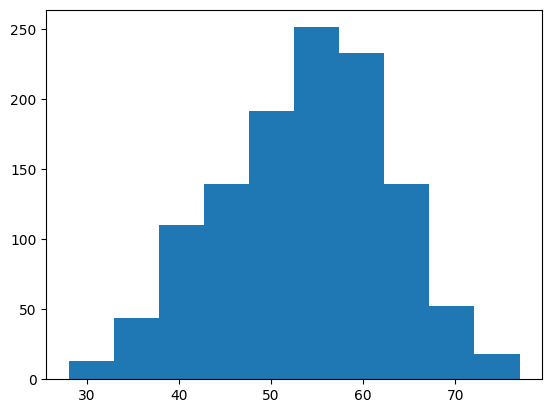

In [ ]:
plt.hist(df['age'])

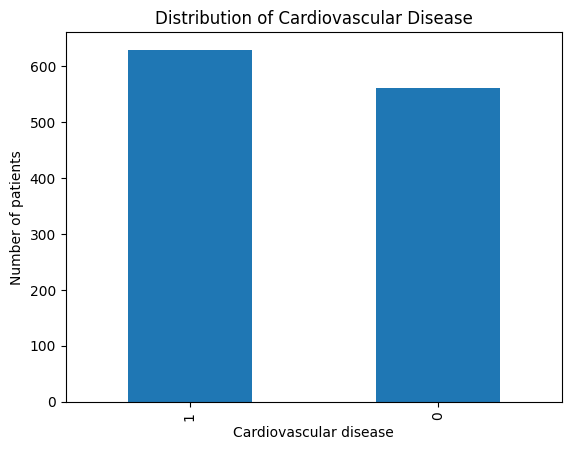

In [16]:
import matplotlib.pyplot as plt

df["target"].value_counts().plot(
    kind="bar"
)

plt.xlabel("Cardiovascular disease")
plt.ylabel("Number of patients")
plt.title("Distribution of Cardiovascular Disease")
plt.show()

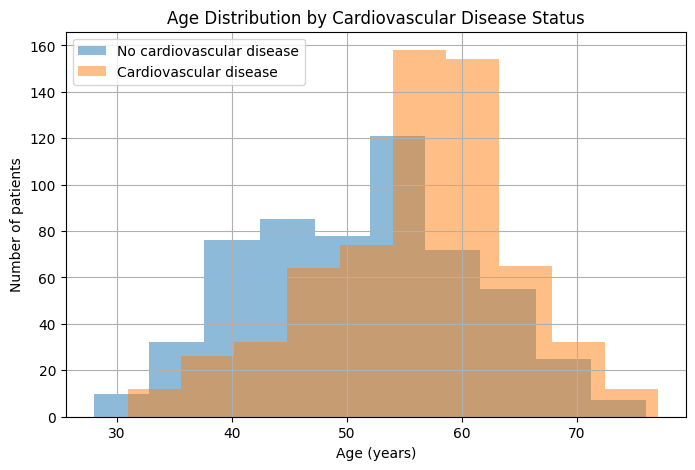

In [18]:
plt.figure(figsize=(8, 5))

df[df["target"] == 0]["age"].hist(
    alpha=0.5,
    label="No cardiovascular disease"
)

df[df["target"] == 1]["age"].hist(
    alpha=0.5,
    label="Cardiovascular disease"
)

plt.xlabel("Age (years)")
plt.ylabel("Number of patients")
plt.title("Age Distribution by Cardiovascular Disease Status")
plt.legend()

plt.show()

<Figure size 800x500 with 0 Axes>

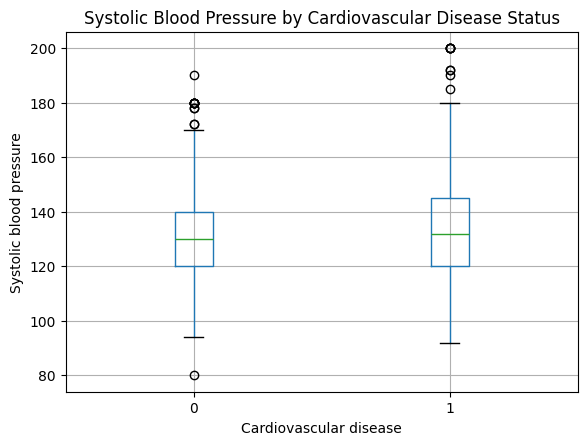

In [19]:
plt.figure(figsize=(8, 5))

df.boxplot(
    column="resting bp s",
    by="target"
)

plt.xlabel("Cardiovascular disease")
plt.ylabel("Systolic blood pressure")
plt.title("Systolic Blood Pressure by Cardiovascular Disease Status")

plt.suptitle("")

plt.show()

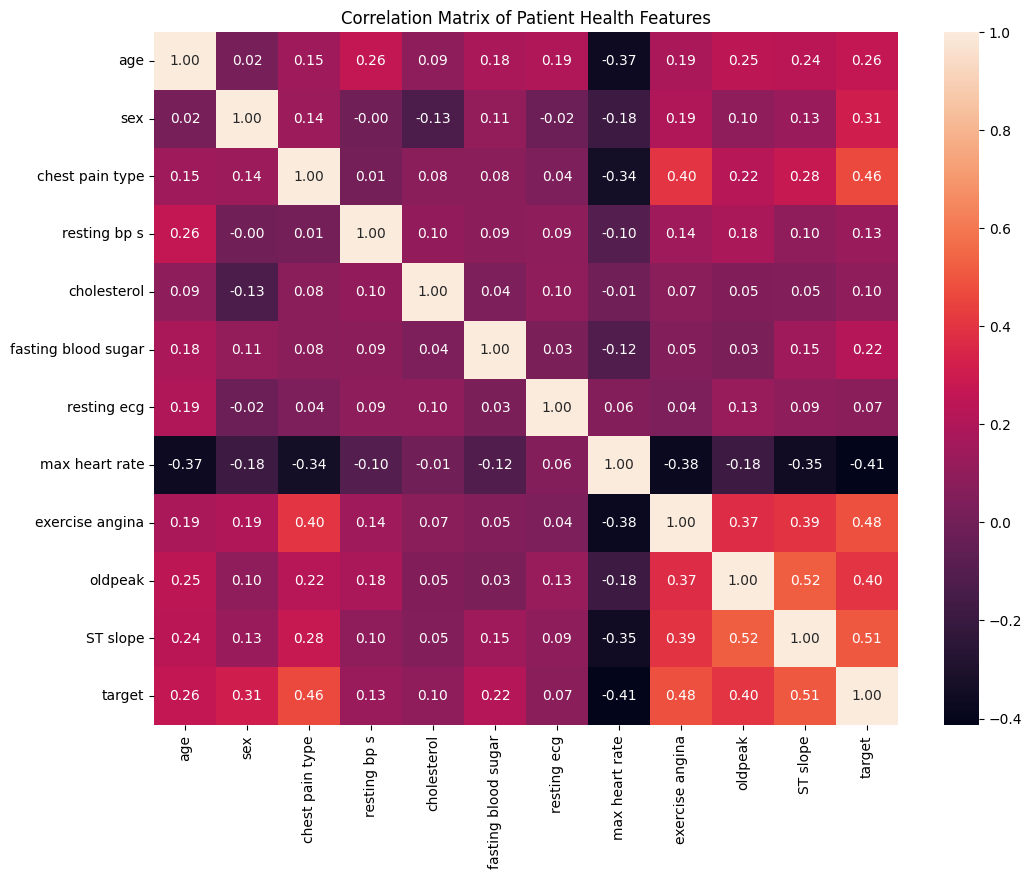

In [26]:
import seaborn as sns

corr = df.corr(numeric_only=True)

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Matrix of Patient Health Features")

plt.show()

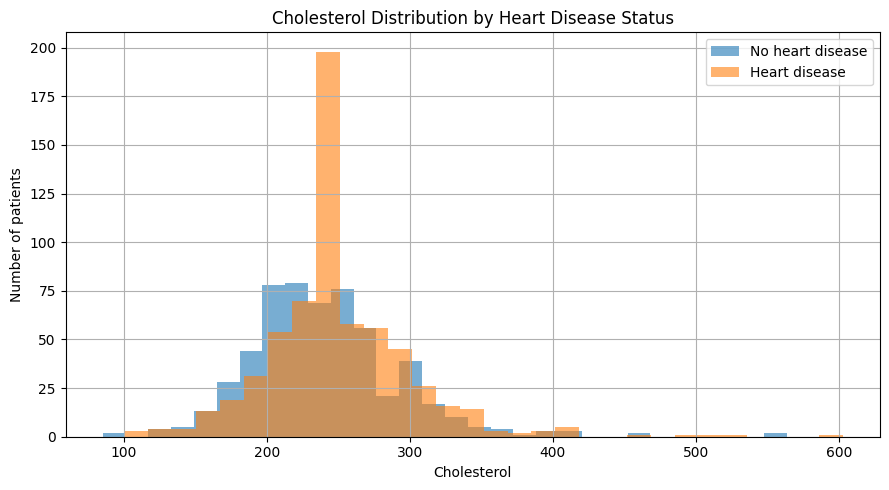

In [23]:
plt.figure(figsize=(9, 5))

df[df["target"] == 0]["cholesterol"].hist(
    bins=30, alpha=0.6, label="No heart disease"
)

df[df["target"] == 1]["cholesterol"].hist(
    bins=30, alpha=0.6, label="Heart disease"
)

plt.xlabel("Cholesterol")
plt.ylabel("Number of patients")
plt.title("Cholesterol Distribution by Heart Disease Status")
plt.legend()
plt.tight_layout()
plt.show()

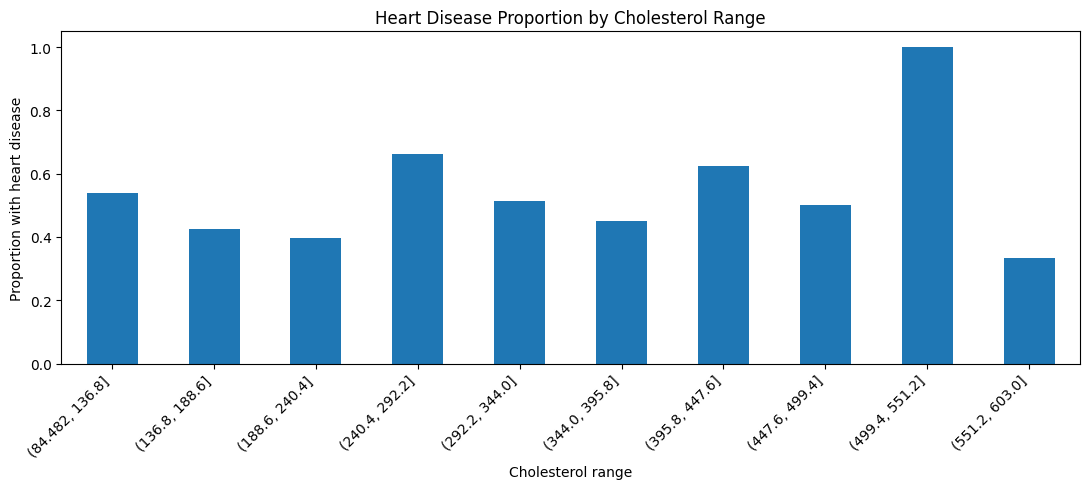

In [27]:
df["cholesterol_bin"] = pd.cut(df["cholesterol"], bins=10)

risk_by_cholesterol = df.groupby(
    "cholesterol_bin", observed=True
)["target"].mean()

risk_by_cholesterol.plot(kind="bar", figsize=(11, 5))

plt.xlabel("Cholesterol range")
plt.ylabel("Proportion with heart disease")
plt.title("Heart Disease Proportion by Cholesterol Range")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

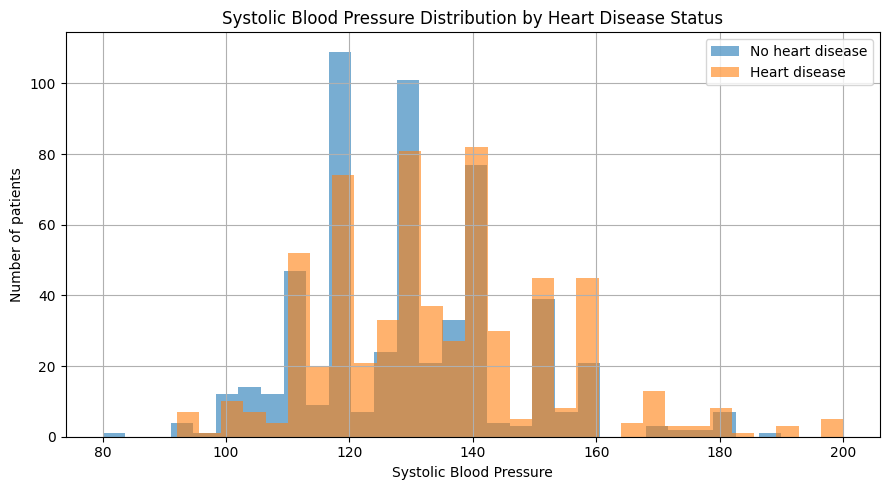

In [28]:
plt.figure(figsize=(9, 5))

df[df["target"] == 0]["resting bp s"].hist(
    bins=30, alpha=0.6, label="No heart disease"
)

df[df["target"] == 1]["resting bp s"].hist(
    bins=30, alpha=0.6, label="Heart disease"
)

plt.xlabel("Systolic Blood Pressure")
plt.ylabel("Number of patients")
plt.title("Systolic Blood Pressure Distribution by Heart Disease Status")
plt.legend()
plt.tight_layout()
plt.show()

In [39]:
X = df.drop(["target", "cholesterol_bin"], axis=1) #features
y = df["target"]



In [32]:
X

,age,sex,chest pain type,resting bp s,cholesterol,fasting blood sugar,resting ecg,max heart rate,exercise angina,oldpeak,ST slope
0,40,1,2,140,289,0,0,172,0,0.0,1
1,49,0,3,160,180,0,0,156,0,1.0,2
2,37,1,2,130,283,0,1,98,0,0.0,1
3,48,0,4,138,214,0,0,108,1,1.5,2
4,54,1,3,150,195,0,0,122,0,0.0,1
...,...,...,...,...,...,...,...,...,...,...,...
1185,45,1,1,110,264,0,0,132,0,1.2,2
1186,68,1,4,144,193,1,0,141,0,3.4,2
1187,57,1,4,130,131,0,0,115,1,1.2,2
1188,57,0,2,130,236,0,2,174,0,0.0,2


In [43]:
y

0       0
1       1
2       0
3       1
4       0
       ..
1185    1
1186    1
1187    1
1188    1
1189    0
Name: target, Length: 1190, dtype: int64